`muller_plots.ipynb`

This file generates Muller plots of Jenna's data. This file was written by Connor for his poster.

In [13]:
import visualize

import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
experiment = '09.22.2025_11.59_AM'
file = f'./experiments/{experiment}/final_data.csv'

In [15]:
data = pd.read_csv(file)

fishes = data['fish'].unique()

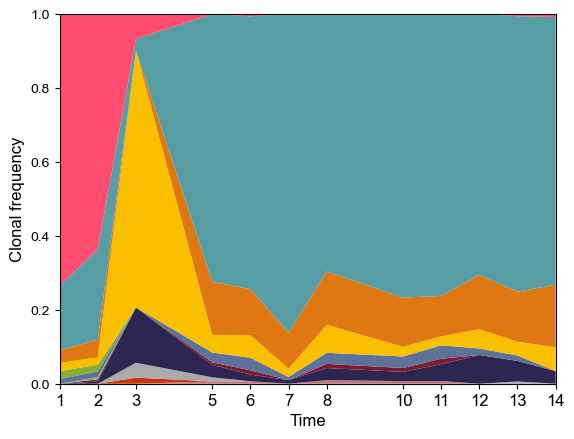

In [16]:
fig, ax = plt.subplots()
visualize.plot(data, 'fish1', ax = ax, replicate = 3)

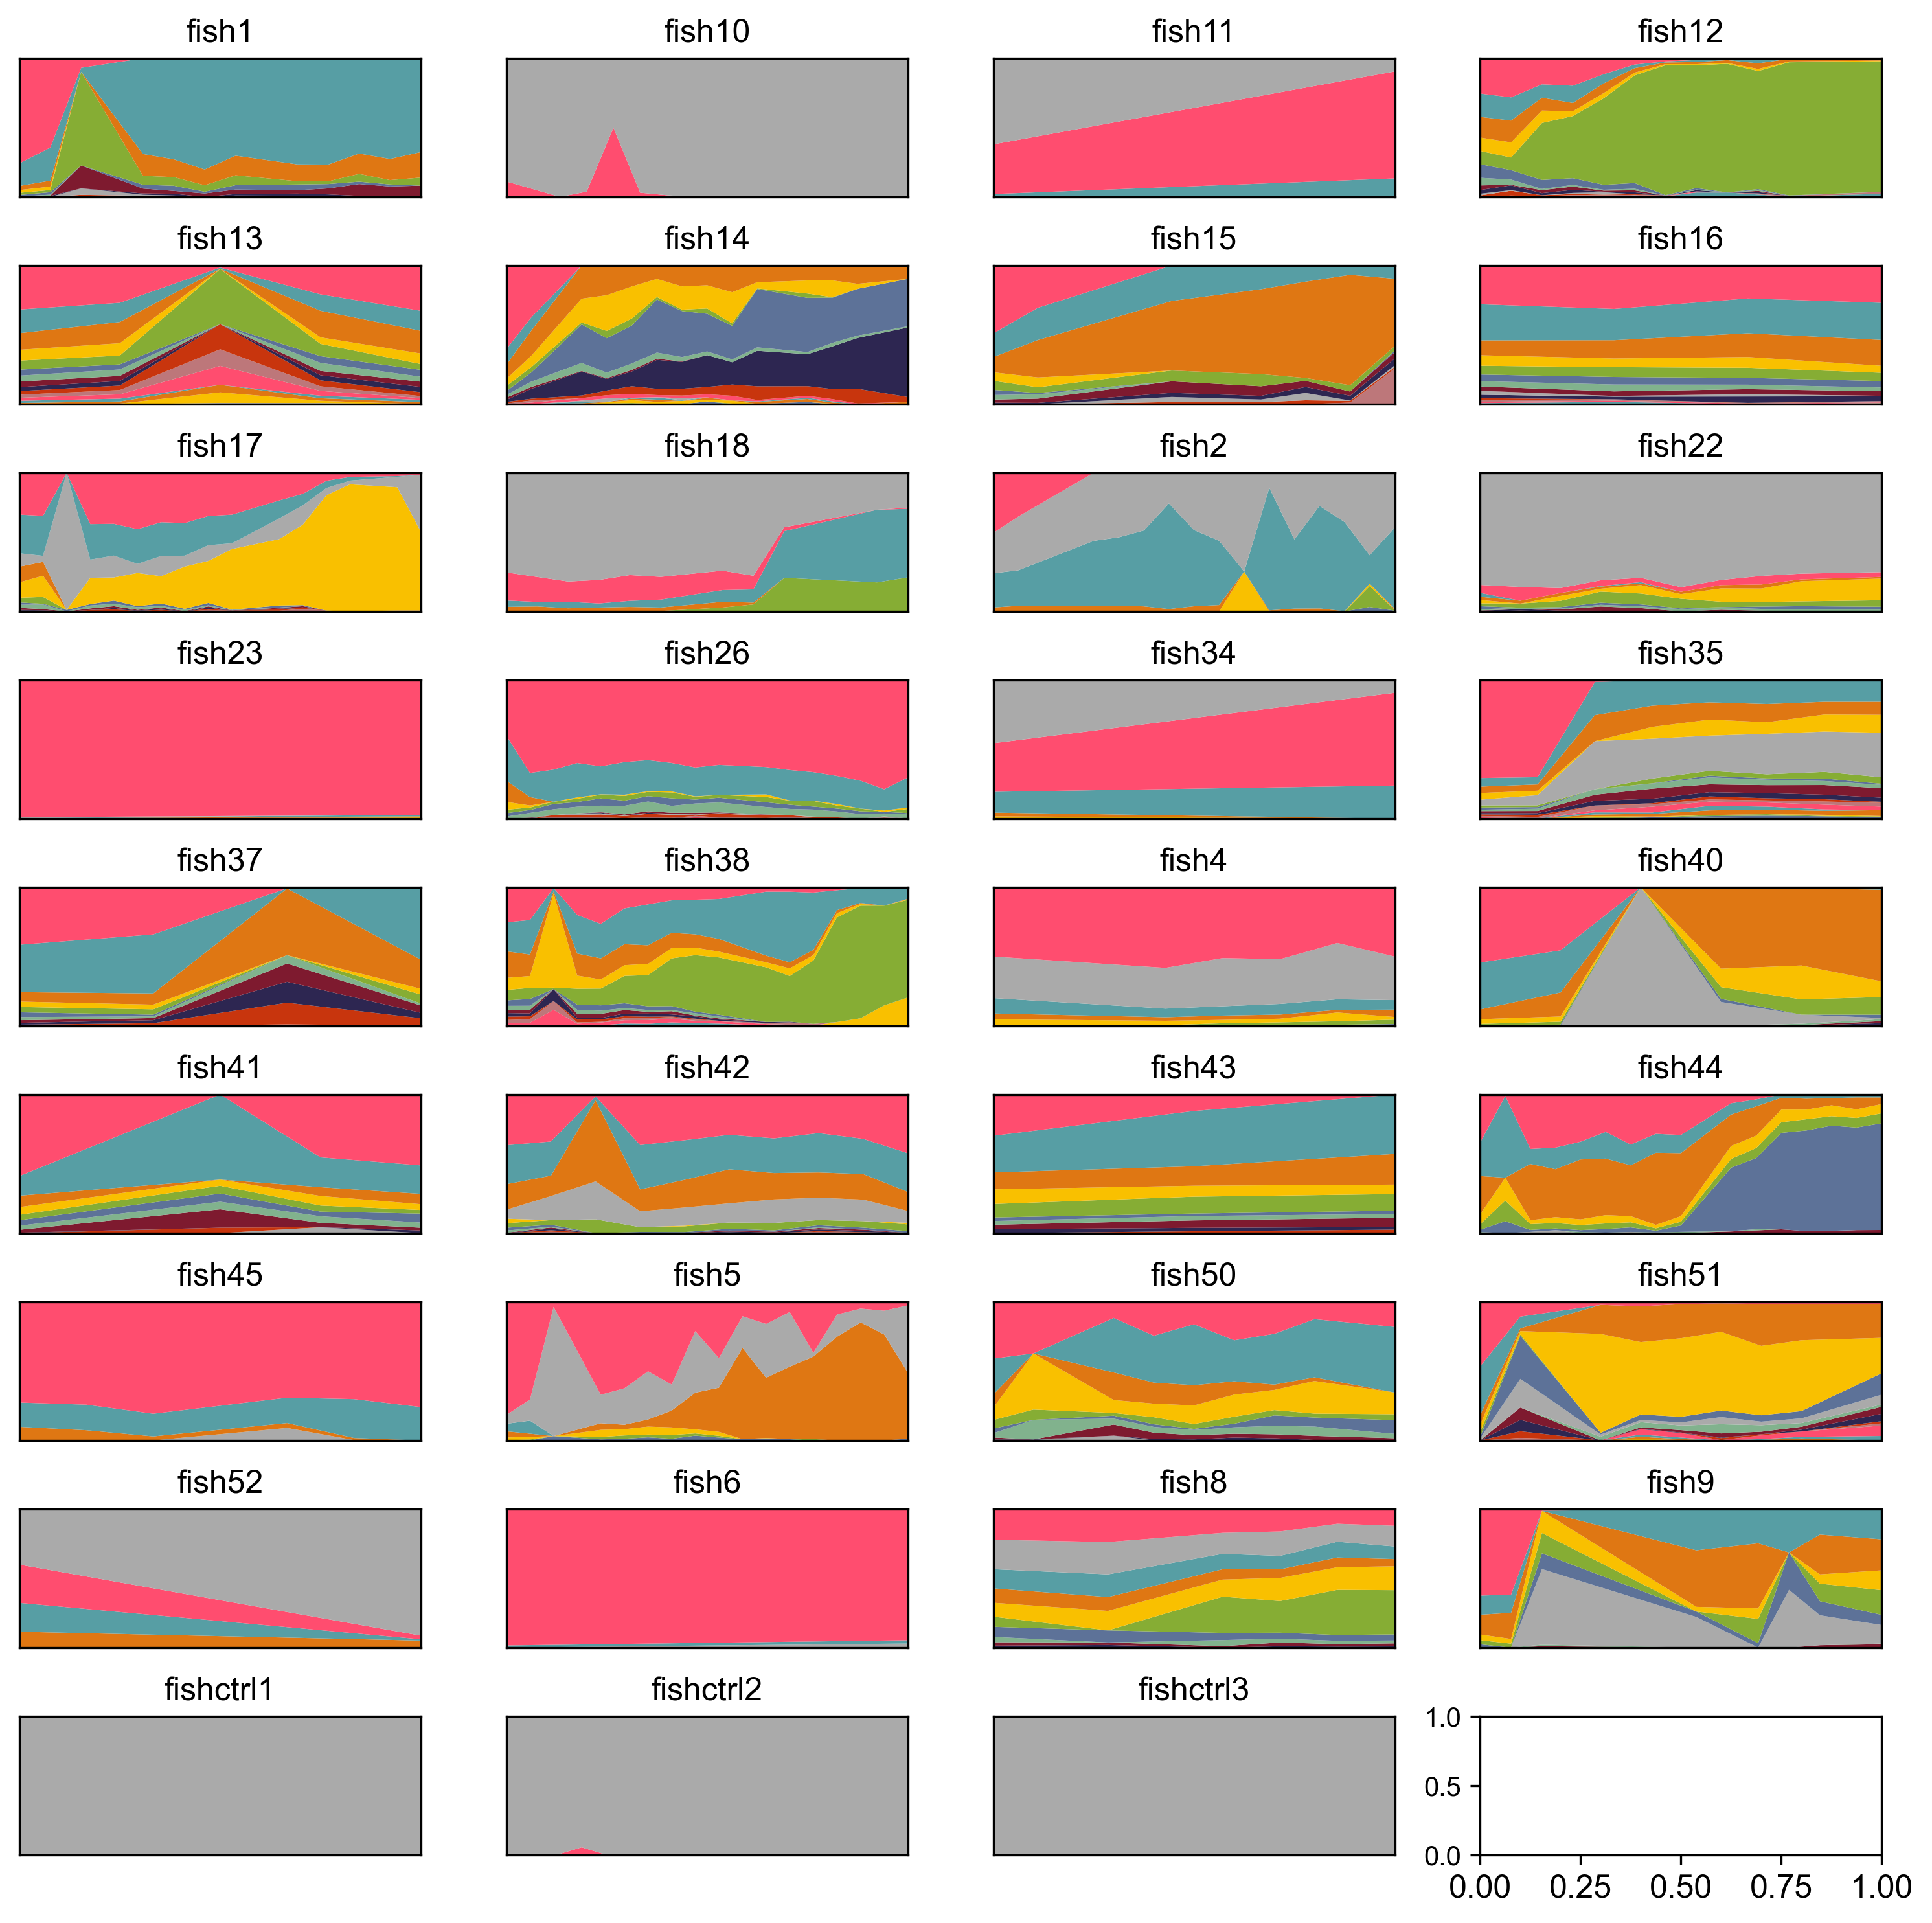

In [17]:
# importlib.reload(tm.data_processing)

# fishes = ['fish4', 'fish5']

fig, ax = plt.subplots(9, 4, figsize = (10, 10), dpi=300)
ax_line = ax.ravel()

for i, fish in enumerate(fishes):
    # fish_data = data.query('fish == @fish').copy()
    # barcodes = data_processing.get_barcodes(fish_data)
    # unedited_index = data_processing.where_unedited(barcodes)
    # fish_table = data_processing.convert_data_to_results(fish_data, barcodes)
    
    # visualize.plot(fish_table, ax_line[i], unedited_index = unedited_index)

    visualize.plot(data, fish, ax_line[i])

    ax_line[i].set_title(fish)
    ax_line[i].set_xlabel('')
    ax_line[i].set_ylabel('')
    ax_line[i].set_yticks([])
    ax_line[i].set_xticks([])
    
plt.tight_layout()
# plt.savefig('cluster-results.png')

In [18]:
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.labelsize'] = 12  # Axis label size
plt.rcParams['xtick.labelsize'] = 12  # X tick label size
plt.rcParams['ytick.labelsize'] = 10  # Y tick label size

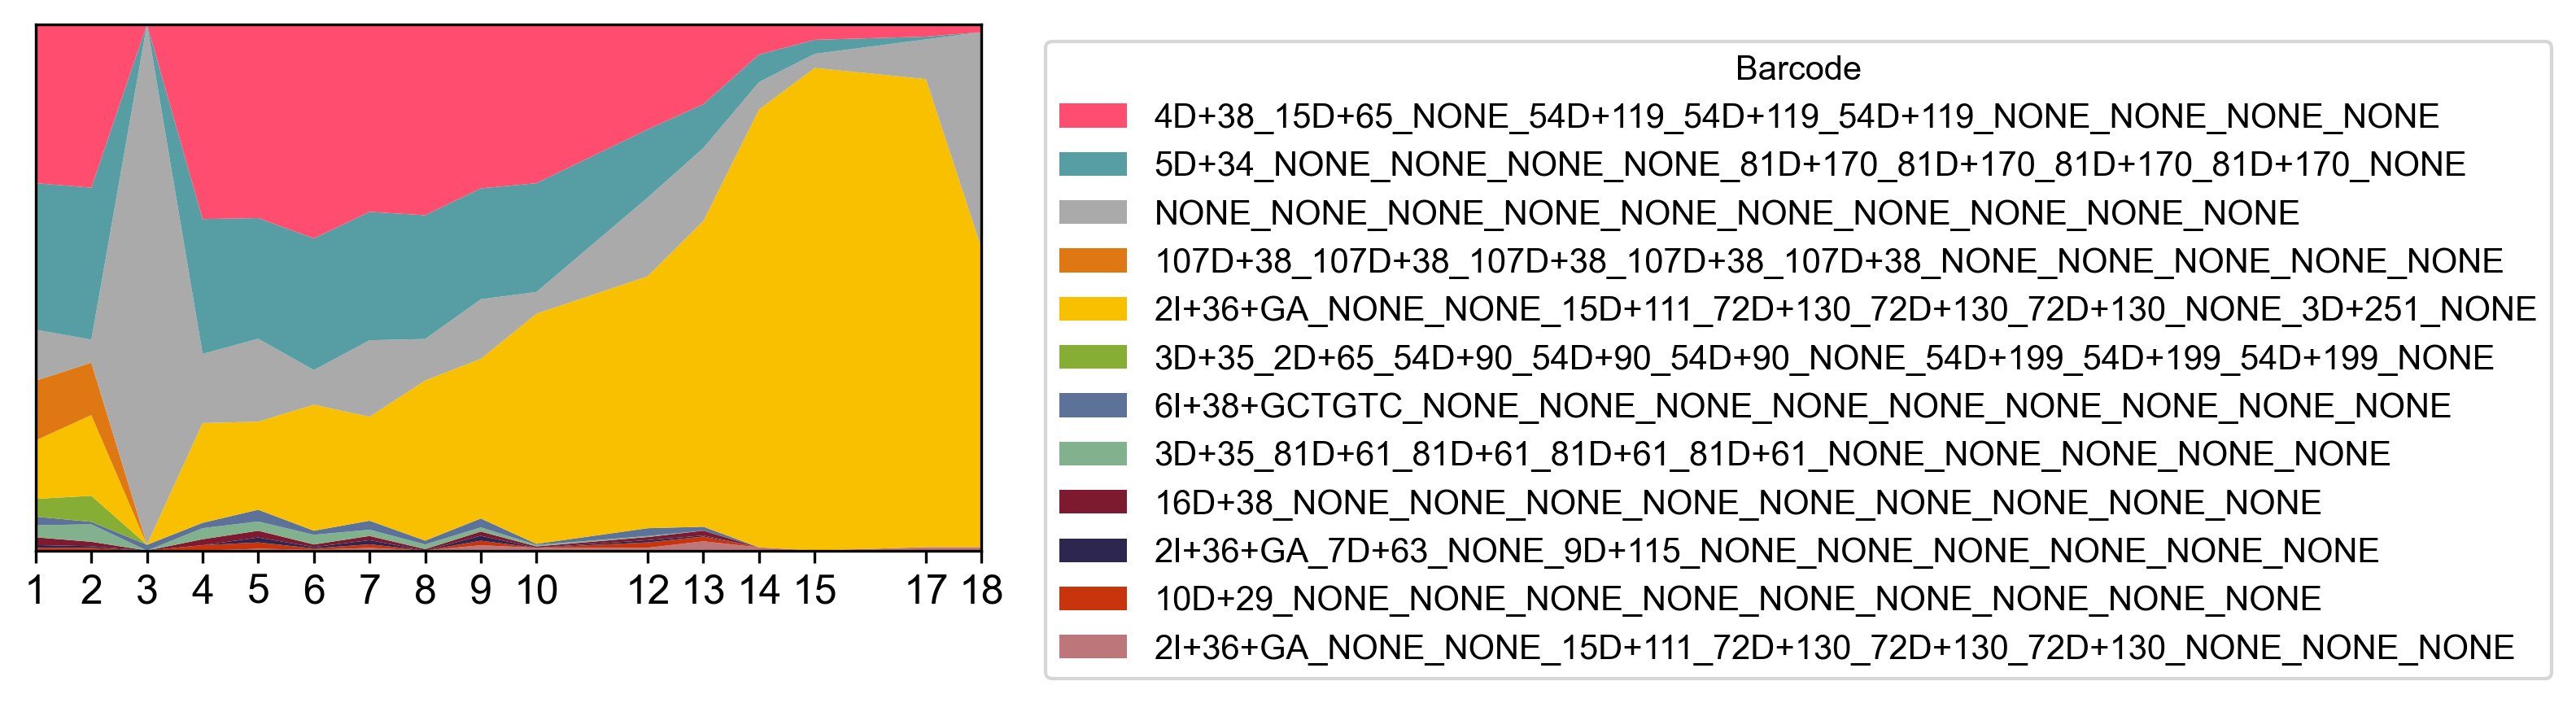

In [19]:
fish = 'fish17'
fig, ax = plt.subplots(figsize=(5, 2.8), dpi=300)

visualize.plot(data, fish, ax, offset_time = 4, add_legend = True)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticks([])
plt.savefig(f'./images/{fish}.png', bbox_inches='tight', transparent=True)

In [8]:
experiment = '08.05.2025_02.49_PM'
data_file = f'./experiments/{experiment}/final_data.csv'
data = pd.read_csv(data_file)
fishes = data['fish'].unique()

import os
info_df = pd.DataFrame({'sample' : [], 'usedEntries' : [], 'totalEntries' : [], 'dir' : []})
for dire in os.listdir('data/mergedinfos'):
    if 'OUTPUT' in dire:
        path = f'data/mergedinfos/{dire}/html'
        inners = os.listdir(f'{path}')
        if '.DS_Store' in inners:
            inners.remove('.DS_Store')
        new_df = pd.read_csv(f'{path}/{inners[0]}/merged.info', sep='\t')
        new_df['dir'] = dire
        info_df = pd.concat([info_df, new_df])
info_df['file'] = info_df['sample']
info_df['usedEntryProp'] = info_df['usedEntries'] / info_df['totalEntries']

map_info = info_df.set_index('file')['usedEntryProp']

data['usedEntryProp'] = data['file'].map(map_info)

data.head()

FileNotFoundError: [Errno 2] No such file or directory: './experiments/08.05.2025_02.49_PM/final_data.csv'

In [ ]:
import seaborn as sb

fish = fishes[5]
plots = 2
fig, ax = plt.subplots(plots, figsize=(8, 4*plots), dpi=300)

fish_data = data.query('fish == @fish').copy()
barcodes = data_processing.get_barcodes(fish_data)
unedited_index = data_processing.where_unedited(barcodes)
fish_table = data_processing.convert_data_to_results(fish_data, barcodes)
visualize.plot(fish_table, ax[0], unedited_index = unedited_index)
ax[0].set_title(f'{fish}')

import math
aggregated_df = fish_data.groupby(['barcode', 'sample']).agg({'proportion': 'mean'}).reset_index().fillna(0)
# Fill in values with 0 where the proportion doesn't exist for a certain barcode/sample combo
pivot_table_df = aggregated_df.pivot_table(index='barcode', columns='sample', values='proportion', fill_value=0).reset_index()
# Interpolate the values for missing samples
final_df_nointerp = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')
final_df = pd.concat([final_df_nointerp, interpolate(final_df_nointerp)])
'''
# Window
window = 2
stds = {'sample' : [], 'barcode' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] >= sample) & (final_df['sample'] < sample + window)]['proportion']
        std = filtered_data.std()
        stds['sample'].append(sample)
        stds['barcode'].append(barcode)
        stds['std'].append(std)
stdf = pd.DataFrame(stds)
sb.lineplot(data=stdf, x='sample', y='std', hue='barcode', ax=ax[1])
plt.title(f'rolling window of size {window}')
ax[1].get_legend().remove()

# fully Rolling
stds_1 = {'sample' : [], 'barcode' : [], 'std' : [], 'direction' : []}
stds_2 = {'sample' : [], 'barcode' : [], 'std' : [], 'direction' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    for barcode in fish_data['barcode'].unique():
        filtered_data_1 = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] <= sample)]['proportion']
        filtered_data_2 = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] >= sample)]['proportion']
        std1 = filtered_data_1.std()
        std2 = filtered_data_2.std()
        stds_1['sample'].append(sample)
        stds_1['barcode'].append(barcode)
        stds_1['std'].append(std1)
        stds_2['sample'].append(sample)
        stds_2['barcode'].append(barcode)
        stds_2['std'].append(std2)
stds_1['direction'] = ['forward'] * len(stds_1['std'])
stds_2['direction'] = ['reverse'] * len(stds_2['std'])
stdf = pd.concat([pd.DataFrame(stds_1), pd.DataFrame(stds_2)]).reset_index()
sb.lineplot(data=stdf, x='sample', y='std', hue='direction', units='barcode', ax=ax[2], estimator=None)
plt.title(f'rolling standard deviation')

# Exclusion
stds = {'sample' : [], 'barcode' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample)]['proportion']
        std = filtered_data.std()
        stds['sample'].append(sample)
        stds['barcode'].append(barcode)
        stds['std'].append(std)
stdf = pd.DataFrame(stds)
sb.lineplot(data=stdf, x='sample', y='std', hue='barcode', ax=ax[3])
plt.title(f'standard deviation excluding element')
ax[3].get_legend().remove()

# Exclusion with window
window = 2
stds = {'sample' : [], 'barcode' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        std = filtered_data.std()
        stds['sample'].append(sample)
        stds['barcode'].append(barcode)
        stds['std'].append(std)
stdf = pd.DataFrame(stds)
sb.lineplot(data=stdf, x='sample', y='std', hue='barcode', ax=ax[4])
plt.title(f'rolling window of size {2*window + 1} excluding middle element')
ax[4].get_legend().remove()
'''

# Difference between window and exclusion with window
window = 2
stds = {'sample' : [], 'barcode' : [], 'val' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    for barcode in fish_data['barcode'].unique():
        filtered_data_included = final_df[(final_df['barcode'] == barcode) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        filtered_data_excluded = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        std_included = filtered_data_included.std()
        std_excluded = filtered_data_excluded.std()
        stds['sample'].append(sample)
        stds['barcode'].append(barcode)
        stds['val'].append(std_included - std_excluded)
stdf = pd.DataFrame(stds)
sb.lineplot(data=stdf, x='sample', y='val', hue='barcode', ax=ax[1])
plt.title(f'rolling window of size {2*window + 1}, minus window excluding middle element')
ax[1].get_legend().remove()

plt.tight_layout()

In [ ]:
fish = fishes[0]
fig, ax = plt.subplots(dpi=300)

fish_data = data.query('fish == @fish').copy()
barcodes = data_processing.get_barcodes(fish_data)
unedited_index = data_processing.where_unedited(barcodes)
fish_table = data_processing.convert_data_to_results(fish_data, barcodes)
visualize.plot(fish_table, ax, unedited_index = unedited_index)
ax.set_title(f'{fish}')
plt.tight_layout()

import math
aggregated_df = fish_data.groupby(['barcode', 'sample']).agg({'proportion': 'mean'}).reset_index().fillna(0)
# Fill in values with 0 where the proportion doesn't exist for a certain barcode/sample combo
pivot_table_df = aggregated_df.pivot_table(index='barcode', columns='sample', values='proportion', fill_value=0).reset_index()
final_df_nointerp = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')
final_df = pd.concat([final_df_nointerp, interpolate(final_df_nointerp)])
#final_df = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')

'''
# Window
window = 2
stds = {'sample' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    sum_std = 0
    nans = 0
    total = 0
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] >= sample) & (final_df['sample'] < sample + window)]['proportion']
        std = filtered_data.std()
        if not math.isnan(std):
            sum_std += std
        else:
            nans += 1
        total += 1
    #print(f'sample {sample} nans: {nans} std: {sum_std / total}')
    stds['sample'].append(sample)
    stds['std'].append(sum_std)
stdf = pd.DataFrame(stds).set_index('sample')
stdf.plot()
plt.title(f'rolling window of size {window}')

# fully Rolling
stds_1 = {'sample' : [], 'std' : []}
stds_2 = {'sample' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    sum_std_1 = 0
    sum_std_2 = 0
    for barcode in fish_data['barcode'].unique():
        filtered_data_1 = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] <= sample)]['proportion']
        filtered_data_2 = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] >= sample)]['proportion']
        sum_std_1 += filtered_data_1.std()
        sum_std_2 += filtered_data_2.std()
    stds_1['sample'].append(sample)
    stds_2['sample'].append(sample)
    stds_1['std'].append(sum_std_1)
    stds_2['std'].append(sum_std_2)
stdf1 = pd.DataFrame(stds_1).set_index('sample')
stdf2 = pd.DataFrame(stds_2).set_index('sample')
stdf1.columns = ['forward']
stdf2.columns = ['reverse']
ax = stdf1.plot(label='forward')
stdf2.plot(label='reverse', ax=ax)
plt.title(f'rolling standard deviation')

# Exclusion
stds = {'sample' : [], 'std' : []}
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    sum_std = 0
    nans = 0
    total = 0
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample)]['proportion']
        std = filtered_data.std()
        sum_std += std
    #print(f'sample {sample} nans: {nans} std: {sum_std / total}')
    stds['sample'].append(sample)
    stds['std'].append(sum_std)
stdf = pd.DataFrame(stds).set_index('sample')
stdf.plot()
plt.title(f'standard deviation excluding element')

# Exclusion with window
stds = {'sample' : [], 'std' : []}
window = 1
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    sum_std = 0
    for barcode in fish_data['barcode'].unique():
        filtered_data = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        std = filtered_data.std()
        sum_std += std
    stds['sample'].append(sample)
    stds['std'].append(sum_std)
stdf = pd.DataFrame(stds).set_index('sample')
stdf.plot()
plt.title(f'rolling window of size {2*window + 1} excluding middle element')
'''
# Difference between window and Exclusion with window
stds = {'sample' : [], 'std included' : [], 'std excluded' : []}
window = 2
for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
    sum_std_included = 0
    sum_std_excluded = 0
    for barcode in fish_data['barcode'].unique():
        filtered_data_included = final_df[(final_df['barcode'] == barcode) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        filtered_data_excluded = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
        std_included = filtered_data_included.std()
        std_excluded = filtered_data_excluded.std()
        sum_std_included += std_included
        sum_std_excluded += std_excluded
    stds['sample'].append(sample)
    stds['std included'].append(sum_std_included)
    stds['std excluded'].append(sum_std_excluded)
stdf = pd.DataFrame(stds).set_index('sample')
stdf['val'] = stdf['std included'] - stdf['std excluded']
stdf.plot()
plt.title(f'rolling window of size {2*window + 1}, minus window excluding middle element')

In [ ]:
def get_missing_values(arr):
    missing = []
    for val in range(arr.min(), arr.max()):
        if not val in arr:
            missing.append(val)
    return np.array(missing)

def interpolate(df):
    concat = {'barcode': [], 'sample': [], 'proportion': []}
    barcodes = df['barcode'].unique()
    for barcode in barcodes:
        x_known = df['sample'].astype('int32').unique()
        y_known = np.array(df[df['barcode'] == barcode]['proportion'], dtype='float64')
        x_desired = get_missing_values(x_known)
        interpolated_values = np.interp(x_desired, x_known, y_known)
        # Add interpolated values to the dataframe
        concat['barcode'] += [barcode] * len(interpolated_values)
        concat['sample'] += x_desired.tolist()
        concat['proportion'] += interpolated_values.tolist()
    return pd.DataFrame(concat)

In [ ]:
def plot_fish(fish, ax, abnormalities = []):
    fish_data = data.query('fish == @fish').copy()
    fish_data = fish_data[~fish_data['sample'].isin(abnormalities)]
    barcodes = data_processing.get_barcodes(fish_data)
    unedited_index = data_processing.where_unedited(barcodes)
    fish_table = data_processing.convert_data_to_results(fish_data, barcodes)
    visualize.plot(fish_table, ax, unedited_index = unedited_index)
    ax.set_title(f'{fish}')
    plt.tight_layout()

def show_abnormalities(index, axis, interp = True):
    fish = fishes[index]
    fish_data = data.query('fish == @fish').copy()
    aggregated_df = fish_data.groupby(['barcode', 'sample']).agg({'proportion': 'mean'}).reset_index().fillna(0)
    # Fill in values with 0 where the proportion doesn't exist for a certain barcode/sample combo
    pivot_table_df = aggregated_df.pivot_table(index='barcode', columns='sample', values='proportion', fill_value=0).reset_index()
    if interp:
        final_df_nointerp = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')
        final_df = pd.concat([final_df_nointerp, interpolate(final_df_nointerp)])
    else:
        final_df = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')
    
    # Difference between window and Exclusion with window
    stds = {'sample' : [], 'std included' : [], 'std excluded' : []}
    window = 2
    for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
        sum_std_included = 0
        sum_std_excluded = 0
        for barcode in fish_data['barcode'].unique():
            filtered_data_included = final_df[(final_df['barcode'] == barcode) & (abs(final_df['sample'] - sample) <= window)]['proportion']
            filtered_data_excluded = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
            std_included = filtered_data_included.std()
            std_excluded = filtered_data_excluded.std()
            sum_std_included += std_included
            sum_std_excluded += std_excluded
        stds['sample'].append(sample)
        stds['std included'].append(sum_std_included)
        stds['std excluded'].append(sum_std_excluded)
    stdf = pd.DataFrame(stds).set_index('sample')
    stdf['val'] = stdf['std included'] - stdf['std excluded']
    stdf.plot(ax=axis)
    differences = {}
    for sample in stdf.index:
        left = 0
        right = 0
        if sample - 1 in stdf.index:
            left = stdf.loc[sample,'val'] - stdf.loc[sample - 1,'val']
        if sample + 1 in stdf.index:
            right = stdf.loc[sample,'val'] - stdf.loc[sample + 1,'val']
        differences[sample] = (left, right)
    stdf['abnormality'] = stdf.index.map(lambda sample: differences[sample][0] > 0.2 and differences[sample][1] > 0.2)
    axis.scatter(stdf[stdf['abnormality']].index, stdf[stdf['abnormality']]['val'], color='red', alpha=0.5)
    show_info(fish, axis)
    axis.legend().remove()
    return stdf[stdf['abnormality']].index

def show_info(fish, axis):
    fish_data = data.query('fish == @fish').copy()
    mean = fish_data['usedEntryProp'].mean()
    std = fish_data['usedEntryProp'].std()
    fish_data['outlier'] = fish_data['usedEntryProp'].apply(lambda x: mean - x > 2 * std)
    sns.lineplot(data = fish_data, x='sample', y='usedEntryProp', ax=axis)
    axis.scatter(fish_data[fish_data['outlier']]['sample'], fish_data[fish_data['outlier']]['usedEntryProp'], color='purple', alpha=0.5, sizes=(10, 10))

In [ ]:
fig, ax = plt.subplots(len(fishes), 2, figsize = (5, 1.5*len(fishes)), dpi=300)

for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0])
    #show_abnormalities(i, ax[i, 1])
    abnormalities = show_abnormalities(i, ax[i, 1], interp = False)
    #plot_fish(fish, ax[i, 2], abnormalities = abnormalities)
plt.tight_layout()

In [ ]:
fig, ax = plt.subplots(len(fishes), 2, figsize = (5, 1.5*len(fishes)), dpi=300)

for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0])
    show_abnormalities(i, ax[i, 1], interp = False)
